In [23]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
print(df.isna().sum().sum(), "missing values")
print(df["Class"].value_counts())
print(df["Class"].mean())
print("Time range (hours):", df["Time"].min() / 3600, "to", df["Time"].max() / 3600)
df.describe().T.head(10)

(284807, 31)
0 missing values
Class
0    284315
1       492
Name: count, dtype: int64
0.001727485630620034
Time range (hours): 0.0 to 47.99777777777778


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


<Axes: xlabel='Class'>

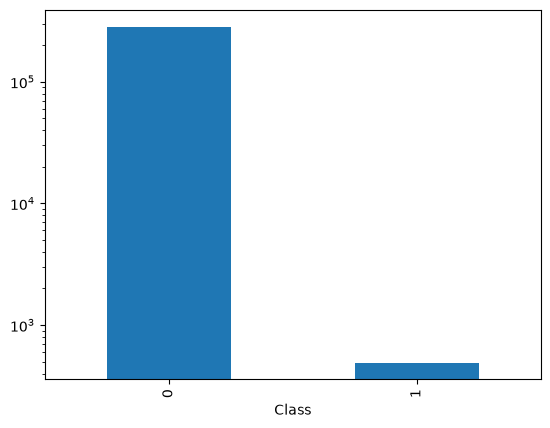

In [24]:
df["Class"].value_counts().plot(kind="bar", logy=True)

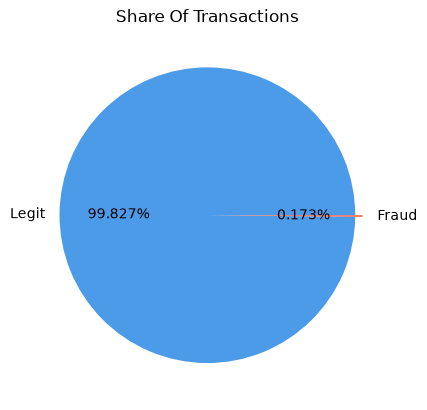

In [25]:
counts = df["Class"].value_counts().sort_index() 

plt.pie(counts, labels=["Legit", "Fraud"], autopct="%1.3f%%",
          explode=(0, 0.05), colors=["#4c9be8", "#e8604c"])
plt.title("Share Of Transactions")
plt.show()

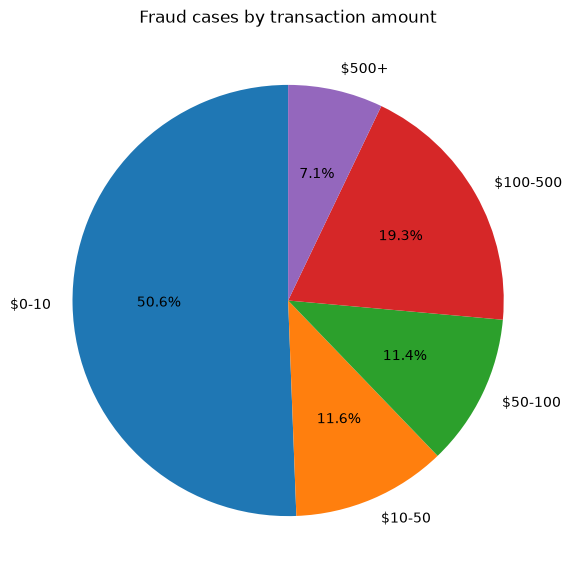

In [26]:
bins = [0, 10, 50, 100, 500, np.inf]
names = ["$0-10", "$10-50", "$50-100", "$100-500", "$500+"]
df["amt_bucket"] = pd.cut(df["Amount"], bins=bins, labels=names, include_lowest=True)

fraud_amt = df[df["Class"] == 1]["amt_bucket"].value_counts().reindex(names)

plt.figure(figsize=(7, 7))
plt.pie(fraud_amt, labels=fraud_amt.index, autopct="%1.1f%%", startangle=90)
plt.title("Fraud cases by transaction amount")
plt.show()

Time Vs Fraud Curve - Shows around what time max transactions were fraudulent (around 1-4 AM)

<Axes: xlabel='hour'>

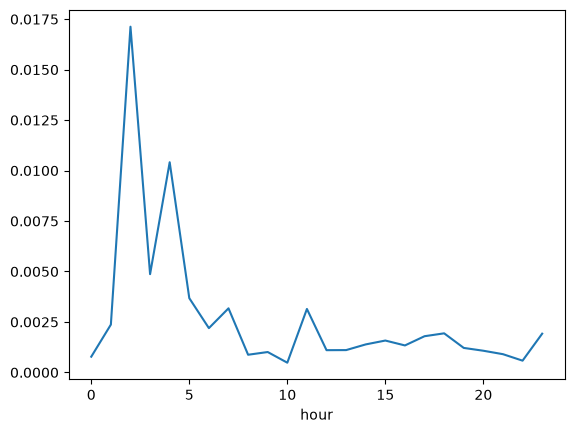

In [27]:
df["hour"] = (df["Time"] // 3600) % 24
df.groupby("hour")["Class"].mean().plot()

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


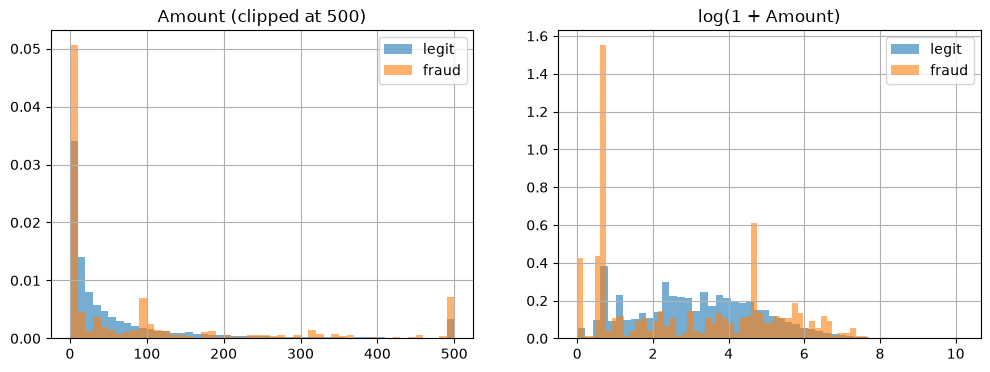

In [28]:
print(df.groupby("Class")["Amount"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[df.Class == 0]["Amount"].clip(upper=500).hist(bins=50, alpha=.6, label="legit", ax=ax[0], density=True)
df[df.Class == 1]["Amount"].clip(upper=500).hist(bins=50, alpha=.6, label="fraud", ax=ax[0], density=True)
ax[0].set_title("Amount (clipped at 500)"); ax[0].legend()

np.log1p(df[df.Class == 0]["Amount"]).hist(bins=50, alpha=.6, label="legit", ax=ax[1], density=True)
np.log1p(df[df.Class == 1]["Amount"]).hist(bins=50, alpha=.6, label="fraud", ax=ax[1], density=True)
ax[1].set_title("log(1 + Amount)"); ax[1].legend()
plt.show()